# Rock vs Mine Classification

## 1. Project Introduction
This project aims at comparing several models to predict whether the object is rock or mine based on the 60 detected signals.

## 2. Import Dependencies

In [89]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    GridSearchCV,
    learning_curve
)

from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_classif
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    make_scorer
)

# Reproducibility
RANDOM_STATE = 42

In [53]:
sonar_data = pd.read_csv('sonar_data.csv', header = None)

## Initial Data Inspection

In [54]:
sonar_data.head()

,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [55]:
sonar_data.shape

(208, 61)

In [56]:
sonar_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 61 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       208 non-null    float64
 1   1       208 non-null    float64
 2   2       208 non-null    float64
 3   3       208 non-null    float64
 4   4       208 non-null    float64
 5   5       208 non-null    float64
 6   6       208 non-null    float64
 7   7       208 non-null    float64
 8   8       208 non-null    float64
 9   9       208 non-null    float64
 10  10      208 non-null    float64
 11  11      208 non-null    float64
 12  12      208 non-null    float64
 13  13      208 non-null    float64
 14  14      208 non-null    float64
 15  15      208 non-null    float64
 16  16      208 non-null    float64
 17  17      208 non-null    float64
 18  18      208 non-null    float64
 19  19      208 non-null    float64
 20  20      208 non-null    float64
 21  21      208 non-null    float64
 22  22      208 n

## Exploratory Data Analysis

In [57]:
sonar_data.describe()

,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
count,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,...,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000
mean,0.029164,0.038437,0.043832,0.053892,0.075202,0.104570,0.121747,0.134799,0.178003,0.208259,...,0.016069,0.013420,0.010709,0.010941,0.009290,0.008222,0.007820,0.007949,0.007941,0.006507
std,0.022991,0.032960,0.038428,0.046528,0.055552,0.059105,0.061788,0.085152,0.118387,0.134416,...,0.012008,0.009634,0.007060,0.007301,0.007088,0.005736,0.005785,0.006470,0.006181,0.005031
min,0.001500,0.000600,0.001500,0.005800,0.006700,0.010200,0.003300,0.005500,0.007500,0.011300,...,0.000000,0.000800,0.000500,0.001000,0.000600,0.000400,0.000300,0.000300,0.000100,0.000600
25%,0.013350,0.016450,0.018950,0.024375,0.038050,0.067025,0.080900,0.080425,0.097025,0.111275,...,0.008425,0.007275,0.005075,0.005375,0.004150,0.004400,0.003700,0.003600,0.003675,0.003100
50%,0.022800,0.030800,0.034300,0.044050,0.062500,0.092150,0.106950,0.112100,0.152250,0.182400,...,0.013900,0.011400,0.009550,0.009300,0.007500,0.006850,0.005950,0.005800,0.006400,0.005300
75%,0.035550,0.047950,0.057950,0.064500,0.100275,0.134125,0.154000,0.169600,0.233425,0.268700,...,0.020825,0.016725,0.014900,0.014500,0.012100,0.010575,0.010425,0.010350,0.010325,0.008525
max,0.137100,0.233900,0.305900,0.426400,0.401000,0.382300,0.372900,0.459000,0.682800,0.710600,...,0.100400,0.070900,0.039000,0.035200,0.044700,0.039400,0.035500,0.044000,0.036400,0.043900


In [58]:
sonar_data[60].value_counts()

60
M    111
R     97
Name: count, dtype: int64

In [59]:
sonar_data.isnull().sum().sum()

np.int64(0)

Visualization

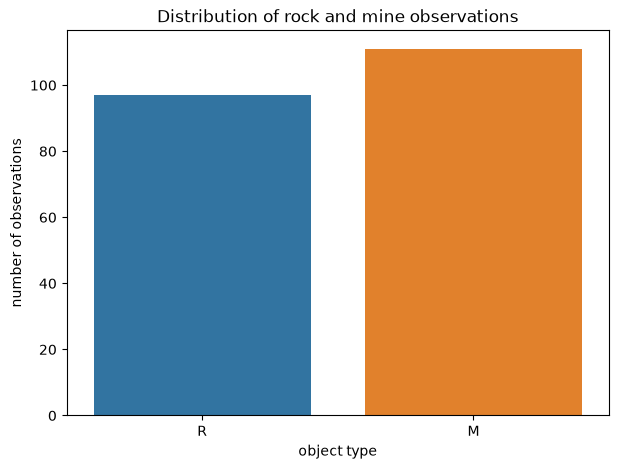

In [61]:
plt.figure(figsize=(7,5))
sns.countplot(
    x = sonar_data[60],
    hue = sonar_data[60],
    legend = False
)

plt.title("Distribution of rock and mine observations")
plt.xlabel("object type")
plt.ylabel("number of observations")

plt.show()

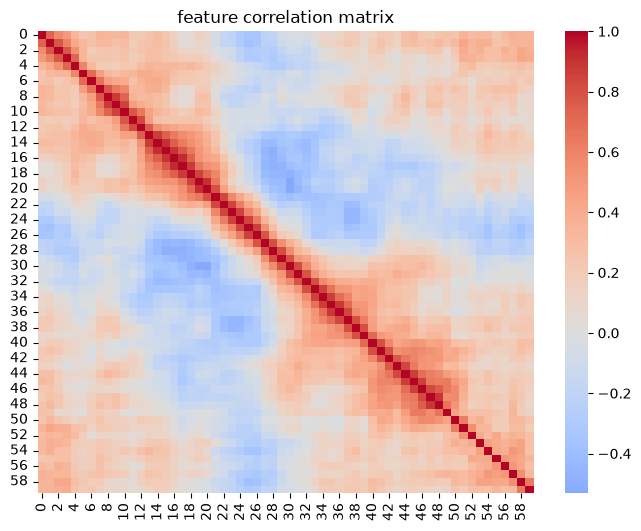

In [62]:
plt.figure(figsize=(8,6))
correlation_matrix = sonar_data.iloc[:, :60].corr()

sns.heatmap(correlation_matrix, cmap = 'coolwarm', center = 0)
plt.title("feature correlation matrix")
plt.show()

## Data preprocessing

In [64]:
X = sonar_data.drop(columns = 60)
y = sonar_data[60]
print('features shape: ', X.shape)
print('target shape: ', y.shape)

features shape:  (208, 60)
target shape:  (208,)


In [65]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = RANDOM_STATE, stratify=y)

## Initial Model Training

In [ ]:
models = {
    'Baseline': DummyClassifier(
        strategy = "most_frequent"
    ),

    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter = 1000,
            random_state = RANDOM_STATE
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ('classifier', SVC(
            kernel = 'rbf',
            random_state = RANDOM_STATE
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators = 200,
        random_state = RANDOM_STATE
    )
}

## Cross-Validation and Model Comparison

In [69]:
cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = RANDOM_STATE
)
scoring = {
    "accuracy": "accuracy",

    "precision": make_scorer(
        precision_score,
        average="macro",
        zero_division=0
    ),

    "recall": "recall_macro",

    "f1": "f1_macro",

    "roc_auc": "roc_auc"
}

results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv = cv, scoring = scoring
    )
    results.append({
        "Model": name, 

        "Accuracy mean": scores["test_accuracy"].mean(),
        "Accuracy std": scores["test_accuracy"].std(),

        "Precision mean": scores["test_precision"].mean(),
        "Precision std": scores["test_precision"].std(),

        "Recall mean": scores["test_recall"].mean(),
        "Recall std": scores["test_recall"].std(),

        "F1 mean": scores['test_f1'].mean(),
        "F1 std": scores["test_f1"].std(),

        "ROC-AUC mean": scores["test_roc_auc"].mean(),
        "ROC-AUC std": scores["test_roc_auc"].std()
    })
results_df = pd.DataFrame(results)
results_df.sort_values(by="F1 mean", ascending = False)

,Model,Accuracy mean,Accuracy std,Precision mean,Precision std,Recall mean,Recall std,F1 mean,F1 std,ROC-AUC mean,ROC-AUC std
2,SVM,0.831373,0.062226,0.845731,0.051583,0.825784,0.064822,0.825950,0.065808,0.922998,0.037417
3,Random Forest,0.825312,0.048398,0.835889,0.047572,0.819395,0.048405,0.821088,0.049889,0.906836,0.043625
1,Logistic Regression,0.735116,0.057756,0.749036,0.069262,0.733562,0.059283,0.730414,0.056674,0.825403,0.068716
0,Baseline,0.536185,0.012215,0.268093,0.006108,0.500000,0.000000,0.348995,0.005210,0.500000,0.000000


## 10. Hyperparameter Optimization

In [70]:
param_grid = {
    "classifier__C": [0.1, 1, 10, 100],

    "classifier__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ],

    "classifier__kernel": [
        "rbf",
        "linear"
    ]
}

In [ ]:
svm_grid = GridSearchCV(
    estimator=models["SVM"],
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    return_train_score=True
)

In [73]:
svm_grid.fit(X_train, y_train)

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1, ...], 'classifier__gamma': ['scale', 0.001, ...], 'classifier__kernel': ['rbf', 'linear']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only 

In [74]:
print("Best parameters:")
print(svm_grid.best_params_)

print("\nBest cross-validation F1:")
print(svm_grid.best_score_)

Best parameters:
{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}

Best cross-validation F1:
0.8578288610824762


In [75]:
svm_results = pd.DataFrame(
    svm_grid.cv_results_
)

svm_results = svm_results.sort_values(
    by="mean_test_score",
    ascending=False
)

svm_results[
    [
        "param_classifier__C",
        "param_classifier__gamma",
        "param_classifier__kernel",
        "mean_train_score",
        "mean_test_score",
        "std_test_score"
    ]
].head(10)

,param_classifier__C,param_classifier__gamma,param_classifier__kernel,mean_train_score,mean_test_score,std_test_score
16,10.0,scale,rbf,1.000000,0.857829,0.033446
24,100.0,scale,rbf,1.000000,0.857829,0.033446
28,100.0,0.01,rbf,1.000000,0.832569,0.052982
20,10.0,0.01,rbf,1.000000,0.832569,0.052982
8,1.0,scale,rbf,0.990939,0.825950,0.065808
12,1.0,0.01,rbf,0.952937,0.807781,0.061275
18,10.0,0.001,rbf,0.893714,0.784466,0.059374
26,100.0,0.001,rbf,0.981822,0.770667,0.067066
17,10.0,scale,linear,1.000000,0.761412,0.056639
29,100.0,0.01,linear,1.000000,0.761412,0.056639


## Learning Curves

In [ ]:
train_sizes, train_scores, validation_scores = learning_curve(
    estimator = best_svm, 
    X = X_train,
    y = y_train,
    cv = cv,
    scoring = "f1_macro",
    train_sizes = np.linspace(0.2, 1.0, 8),
    n_jobs = -1
)

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0

In [84]:
train_mean = train_scores.mean(axis = 1)
train_std = train_scores.std(axis = 1)
validation_mean = validation_scores.mean(axis = 1)
validation_std = validation_scores.std(axis = 1)

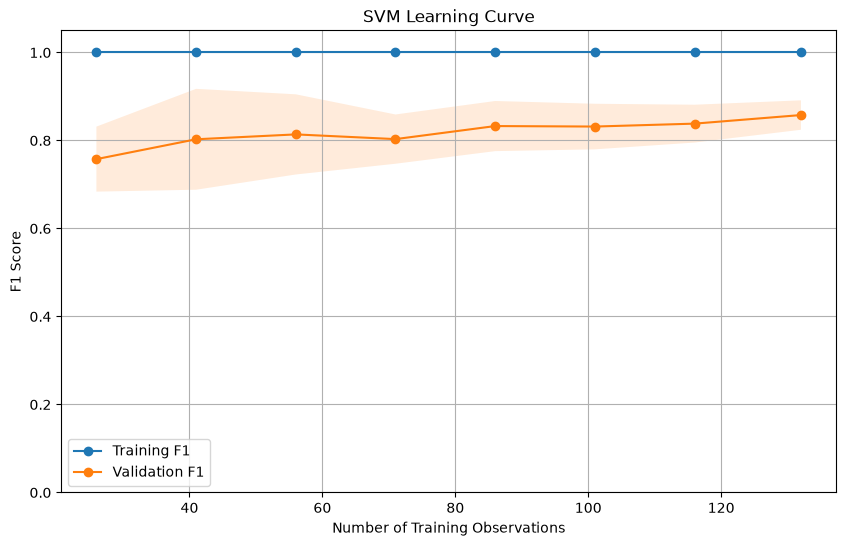

In [90]:
plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training F1"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation F1"
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.xlabel("Number of Training Observations")
plt.ylabel("F1 Score")

plt.title("SVM Learning Curve")

plt.legend()
plt.grid()
plt.ylim(0, 1.05)
plt.show()


## Feature Selection

In [107]:
feature_selection_pipeline = Pipeline([
    ("scaler", StandardScaler()),
        ("selector", SelectKBest(
            score_func=lambda X, y: mutual_info_classif(
                X, y, random_state=RANDOM_STATE
            ),
            k=60
        )
    ),
    ("classifier", SVC(
        C=10,
        gamma = "scale",
        kernel = 'rbf',
        random_state = RANDOM_STATE
    ))
])

In [108]:
param_grid_features = {
    "selector__k": [10, 20, 30, 40, 50, 60]
}

feature_grid = GridSearchCV(
    estimator=feature_selection_pipeline,

    param_grid=param_grid_features,

    cv=cv,

    scoring="f1_macro",

    n_jobs=-1,

    return_train_score=True
)

feature_grid.fit(X_train, y_train)

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - to python to disable frozen modules.
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'selector__k': [10, 20, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specifics

In [109]:
feature_results = pd.DataFrame(
    feature_grid.cv_results_
)

feature_results = feature_results[[
    "param_selector__k",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]]

feature_results = feature_results.sort_values(
    by="mean_test_score",
    ascending=False
)

feature_results

,param_selector__k,mean_train_score,mean_test_score,std_test_score
5,60,1.000000,0.857829,0.033446
4,50,1.000000,0.843305,0.066596
2,30,1.000000,0.820656,0.070878
3,40,1.000000,0.820508,0.085930
1,20,1.000000,0.781555,0.084107
0,10,0.981808,0.773669,0.063204


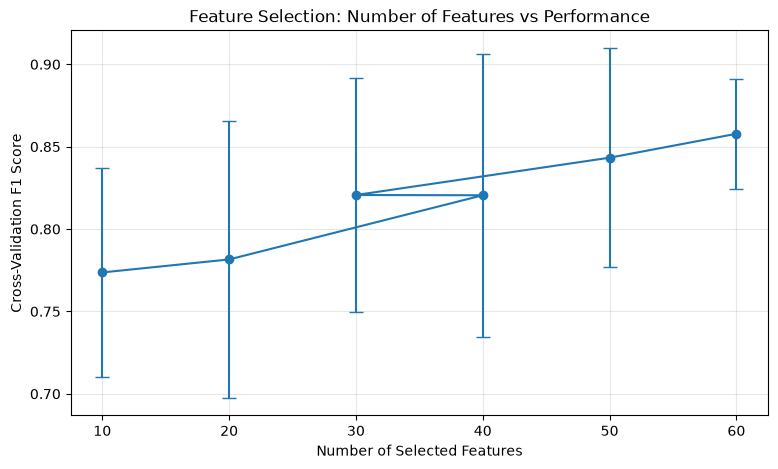

In [110]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    feature_results["param_selector__k"].astype(int),
    feature_results["mean_test_score"],
    yerr=feature_results["std_test_score"],
    marker="o",
    capsize=5
)

plt.xlabel("Number of Selected Features")
plt.ylabel("Cross-Validation F1 Score")

plt.title("Feature Selection: Number of Features vs Performance")

plt.xticks([10, 20, 30, 40, 50, 60])

plt.grid(alpha=0.3)

plt.show()

In [111]:
print("Best number of features:")

print(
    feature_grid.best_params_["selector__k"]
)

print("\nBest cross-validation F1:")

print(feature_grid.best_score_)

Best number of features:
60

Best cross-validation F1:
0.8578288610824762


## Experiment with thresholds

In [113]:
threshold_pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("classifier", SVC(
        C=10,
        gamma="scale",
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

In [114]:
from sklearn.model_selection import cross_val_predict

y_proba = cross_val_predict(
    threshold_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

/Users/polinailusina/Desktop/rockmine/rockmine/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/polinailusina/Desktop/rockmine/rockmine/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/polinailusina/Desktop/rockmine/rockmine/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/polinailusina/Desktop/rockmine/rockmine/.venv/lib/p

In [115]:
classes = np.unique(y_train)
mine_index = np.where(classes == "M")[0][0]

mine_probabilities = y_proba[:, mine_index]

In [116]:
thresholds = np.arange(0.1, 1.0, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = np.where(
        mine_probabilities >= threshold,
        "M",
        "R"
    )

    threshold_results.append({

        "Threshold": threshold,

        "Mine Recall": recall_score(
            y_train,
            y_pred_threshold,
            pos_label="M"
        ),

        "Mine Precision": precision_score(
            y_train,
            y_pred_threshold,
            pos_label="M"
        ),

        "F1": f1_score(
            y_train,
            y_pred_threshold,
            pos_label="M"
        ),

        "False Positive Rate": (
            np.sum((y_train == "R") & (y_pred_threshold == "M"))
            / np.sum(y_train == "R")
        )
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results

,Threshold,Mine Recall,Mine Precision,F1,False Positive Rate
0,0.10,0.988764,0.721311,0.834123,0.441558
1,0.15,0.977528,0.743590,0.844660,0.389610
2,0.20,0.977528,0.763158,0.857143,0.350649
3,0.25,0.977528,0.776786,0.865672,0.324675
4,0.30,0.977528,0.790909,0.874372,0.298701
5,0.35,0.943820,0.800000,0.865979,0.272727
6,0.40,0.932584,0.821782,0.873684,0.233766
7,0.45,0.932584,0.838384,0.882979,0.207792
8,0.50,0.921348,0.845361,0.881720,0.194805
9,0.55,0.910112,0.861702,0.885246,0.168831


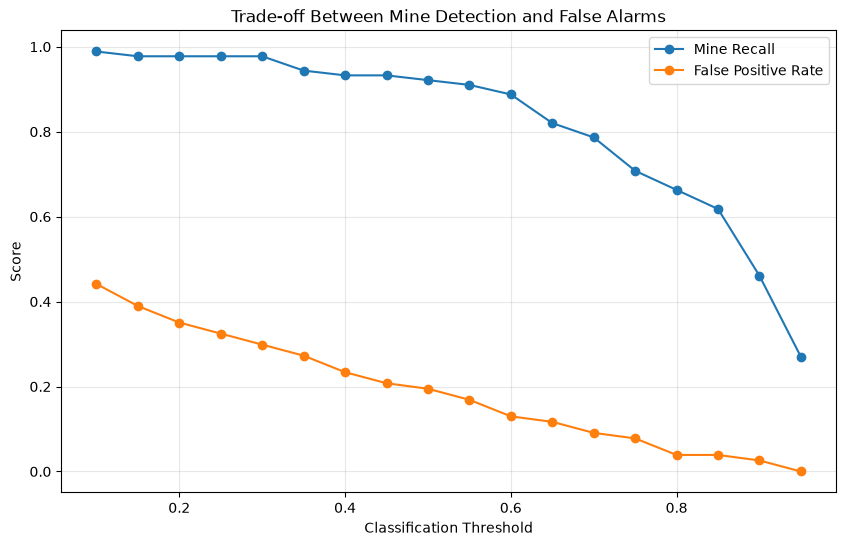

In [117]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Mine Recall"],
    marker="o",
    label="Mine Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["False Positive Rate"],
    marker="o",
    label="False Positive Rate"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title("Trade-off Between Mine Detection and False Alarms")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

## Final model

In [122]:
FINAL_THRESHOLD = 0.30

FINAL_FEATURES = 60

final_model = Pipeline([
    ("scaler", StandardScaler()),

    ("classifier", SVC(
        C=10,
        gamma="scale",
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

In [123]:
final_model.fit(X_train, y_train)

print("Final model trained successfully.")
print("Selected features:", FINAL_FEATURES)
print("Classification threshold:", FINAL_THRESHOLD)

Final model trained successfully.
Selected features: 60
Classification threshold: 0.3


/Users/polinailusina/Desktop/rockmine/rockmine/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [124]:
classes = final_model.named_steps["classifier"].classes_

mine_index = np.where(classes == "M")[0][0]

y_probabilities = final_model.predict_proba(X_test)

mine_probabilities_test = y_probabilities[:, mine_index]

y_pred = np.where(
    mine_probabilities_test >= FINAL_THRESHOLD,
    "M",
    "R"
)
print(classification_report(
    y_test, y_pred, labels = ["M", "R"], target_names = ["Mine", "Rock"]
))

              precision    recall  f1-score   support

        Mine       0.81      0.95      0.88        22
        Rock       0.94      0.75      0.83        20

    accuracy                           0.86        42
   macro avg       0.87      0.85      0.85        42
weighted avg       0.87      0.86      0.86        42



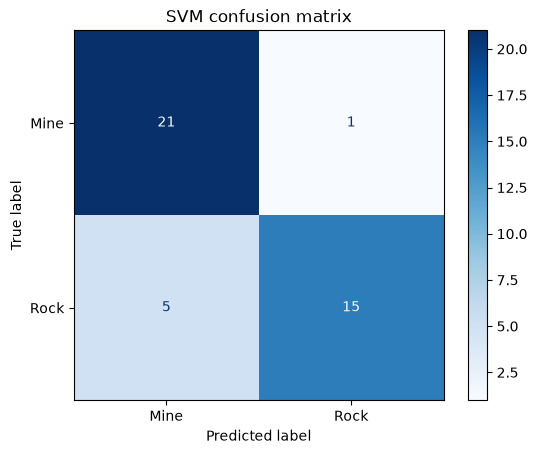

In [125]:
cm = confusion_matrix(y_test, y_pred, labels = ["M", "R"])
disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = ["Mine", "Rock"])
disp.plot(cmap = "Blues")
plt.title("SVM confusion matrix")
plt.show()

## Final Model Selection

The final model was selected based on the results of hyperparameter optimization, feature selection, and classification threshold experiments.

An RBF Support Vector Machine (SVM) was selected with C = 10 and gamma = scale. Feature selection experiments demonstrated that using all 60 available features provided the highest cross-validation F1-score of approximately 0.858.

The classification threshold was adjusted from the default 0.50 to 0.30. This decision prioritizes Mine recall, reducing the likelihood of incorrectly classifying an actual mine as a rock. During threshold experiments, a threshold of 0.30 achieved a Mine recall of approximately 97.8%, with a false positive rate of approximately 29.9%. This threshold provides a better balance for an application where missing a mine is considered particularly costly.

## Model persistance

In [126]:
import joblib

joblib.dump(
    {
        "model": final_model,
        "threshold": FINAL_THRESHOLD,
        "features": list(X.columns),
        "target_classes": ["M", "R"]
    },
    "rock_mine_classifier.pkl"
)

['rock_mine_classifier.pkl']

In [127]:
saved_model = joblib.load(
    "rock_mine_classifier.pkl"
)

loaded_model = saved_model["model"]

loaded_threshold = saved_model["threshold"]

In [132]:
new_probabilities = loaded_model.predict_proba(X_test)

classes = loaded_model.named_steps["classifier"].classes_

mine_index = np.where(classes == "M")[0][0]

predictions = np.where(
    new_probabilities[:, mine_index] >= loaded_threshold,
    "M",
    "R"
)